# Crossing beams and shadow

Two tests of the ray closure in optically thin regions from the IDORT paper (Ma et al. 2025,
sec. 4.1.1 and 4.1.4) and Jiang (2021, ApJS 253, 49, sec. 4.2 and 4.3), with the production
keys (`decks/idort_beams.athinput`, `decks/idort_shadow*.athinput`):

- **crossing beams** in vacuum (`idort_beams`): two beams enter at $x_1 = -2$ at $\pm 45$ deg
  and wrap through the periodic $x_2$ boundary; exact: the straight beams. Also on 4
  MeshBlocks (`idort_beams_mb`, no plot: identical in tile mode).
- **shadow** (`idort_shadow`, ring of 12 rays; `idort_shadow_gl`, the general $8\times32$ set):
  two beams at $\pm15$ deg past an opaque ellipse; exact: the beams attenuated along straight rays.

Criteria: L1 within 5 % of the reference values (`ref/references.json`). Code units.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
ATHENAK = os.path.abspath(os.environ.get('ATHENAK', '../../athenak'))   # your athenak checkout
sys.path.insert(0, os.path.join(ATHENAK, 'tests/vet_clean/notebooks'))
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', os.path.join(ATHENAK, 'build_tests/src/athena')))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('VET_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('VET_NB_THREADS', '4'))   # OpenMP threads per run
nb.style()
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../athenak/build_tests/src/athena 
runs   runs


In [2]:
TESTS = ['idort_beams', 'idort_beams_mb', 'idort_shadow', 'idort_shadow_gl']
res = {t: nb.suite(t, EXE, WORK, THREADS) for t in TESTS}
vett, rt = nb.vett, nb.rt

loading the existing run runs/idort_beams
loading the existing run runs/idort_beams_mb
loading the existing run runs/idort_shadow
loading the existing run runs/idort_shadow_gl


## Crossing beams

Left: E of the run; middle: the exact straight beams (cell averages); right: cuts across the
beams at four heights $x_1$ (black: simulation, red dashed: exact). The beams, 4 cells wide, stay straight
and go on after crossing; they carry 1.19 times the exact energy (`lum_top`), which dominates L1.
Second figure: the same beams 1, 2, 4 and 8 cells wide (4 more short runs, not a suite test): L1 of E
(dashed: 1/width) and the energy of the row three cells below the top over the exact (1 = exact).

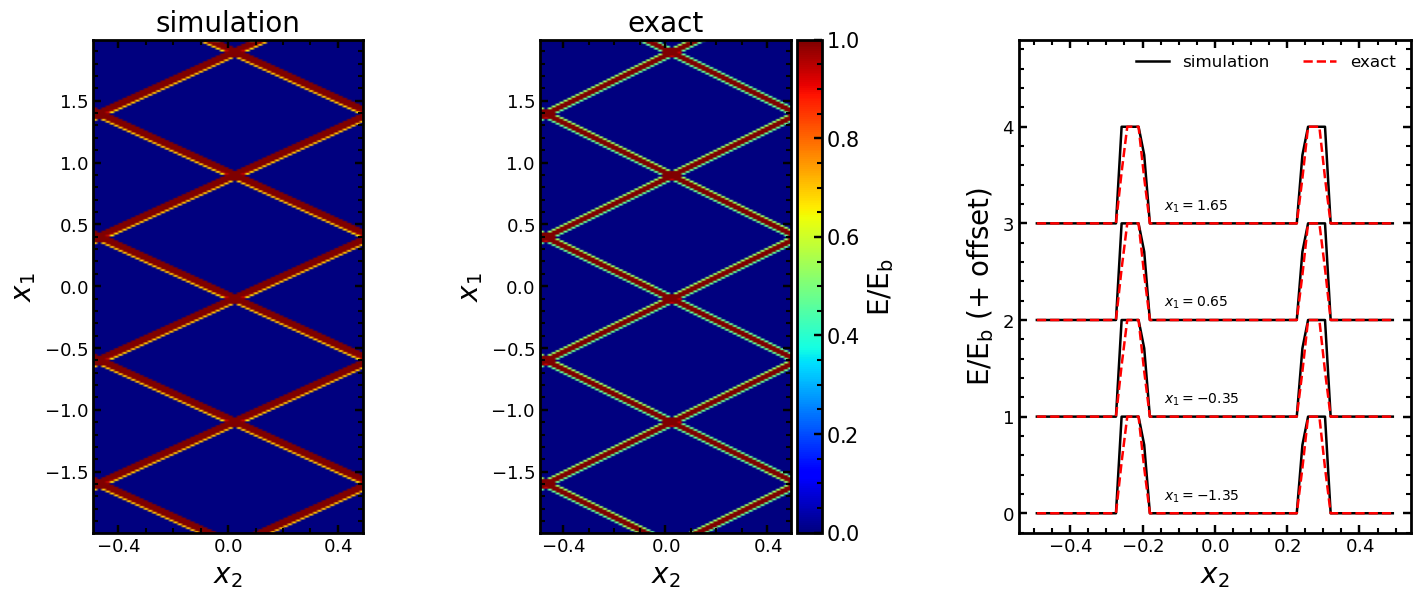

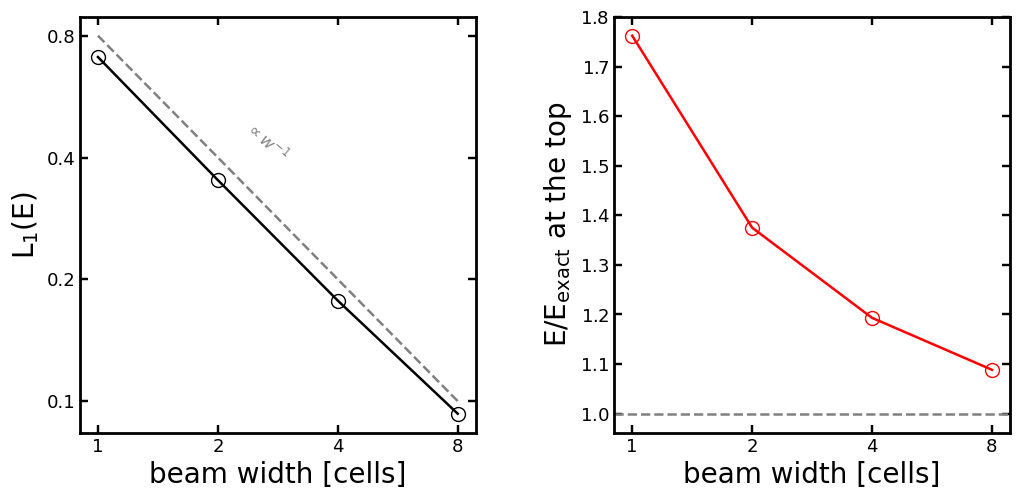

PASS idort_beams   criterion {"max": {"flux_err": 1e-05}, "near": {"L1": [0.1772, 0.05], "lum_top": [1.1932, 0.05]}}
PASS idort_beams_mb   criterion {"equal": {"maxdiff_tile_x2": 0.0}, "max": {"maxdiff_block_x1": 1e-08}}


In [3]:
LB, TK, LG = 20, 15, 12
def bar(fig, im, ax, lab):
    c = fig.colorbar(im, ax=ax, pad=0.02); c.set_label(lab, fontsize=LB); c.ax.tick_params(labelsize=TK)
# ---- beams
d = os.path.join(WORK, 'idort_beams', 'run'); E, Ex = vett.last_bin(d, 'vet')['vet_e'][0], rt.beams_exact(d); x1, x2, _ = vett.cell_centres(d)
fig, ax = plt.subplots(1, 3, figsize=(17, 6.4), gridspec_kw={'width_ratios': [1, 1.12, 1.45], 'wspace': 0.55})
ext = [x2[0], x2[-1], x1[0], x1[-1]]
for a, f, t in ((ax[0], E, 'simulation'), (ax[1], Ex, 'exact')):
    im = a.imshow(f.T, origin='lower', extent=ext, aspect='auto', vmin=0, vmax=1, cmap='jet')
    a.set_xlabel(r'$x_2$', fontsize=LB); a.set_ylabel(r'$x_1$', fontsize=LB); a.set_title(t, fontsize=LB); a.set_xticks([-0.4, 0, 0.4])
bar(fig, im, ax[1], r'$\rm E / E_b$')
for k, r in enumerate((-1.35, -0.35, 0.65, 1.65)):
    i = int(np.argmin(np.abs(x1 - r)))
    ax[2].plot(x2, E[:, i] + k, 'k-', label=r'simulation' if k == 0 else None); ax[2].plot(x2, Ex[:, i] + k, 'r--', label=r'exact' if k == 0 else None)
    ax[2].text(-0.14, k + 0.14, r'$x_1 = %.2f$' % x1[i], fontsize=LG - 2)
ax[2].set_xlabel(r'$x_2$', fontsize=LB); ax[2].set_ylabel(r'$\rm E / E_b$ (+ offset)', fontsize=LB); ax[2].set_ylim(-0.2, 4.9); ax[2].legend(fontsize=LG, loc='upper right', ncol=2)
plt.show()
# the width ladder: the same beams 1, 2, 4 and 8 cells wide (4 short runs; not a suite test)
L = {}
for w in (1, 2, 4, 8):
    d = os.path.join(WORK, 'idort_beams_w%d' % w)
    if not os.path.exists(os.path.join(d, 'run.log')):
        os.makedirs(d, exist_ok=True)
        vett.make_deck(os.path.join(nb.SUITE, 'decks', 'idort_beams.athinput'), os.path.join(d, 'in.athinput'),
                       {'rad_vet/implicit_beam0_y1': -0.109375 + w/64., 'rad_vet/implicit_beam1_y1': 0.09375 + w/64.})
        rc, wall, log = vett.run([EXE], d, ['-i', 'in.athinput'], threads=THREADS)
        assert rc == 0, log[-400:]
    Ew, Exw = vett.last_bin(d, 'vet')['vet_e'][0], rt.beams_exact(d)
    L[w] = dict(L1=rt.l1(Ew, Exw), lum_top=float(Ew[:, -3].sum()/Exw[:, -3].sum()))
w = np.array(sorted(L))
fig, ax = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={'wspace': 0.35})
ax[0].loglog(w, [L[k]['L1'] for k in w], 'ko-', mfc='none', ms=10); ax[0].loglog(w, 0.8/w, '--', c='0.5'); ax[0].text(2.3, 0.39, r'$\propto w^{-1}$', color='0.5', rotation=-41, fontsize=LG)
ax[1].semilogx(w, [L[k]['lum_top'] for k in w], 'ro-', mfc='none', ms=10); ax[1].axhline(1.0, c='0.5', ls='--')
for a, y in zip(ax, (r'$\rm L_1(E)$', r'$\rm E / E_{exact}$ at the top')):
    a.set_xlabel(r'beam width [cells]', fontsize=LB); a.set_ylabel(y, fontsize=LB); a.set_xticks(w); a.set_xticklabels([str(k) for k in w]); a.minorticks_off()
ax[0].set_yticks([0.1, 0.2, 0.4, 0.8]); ax[0].set_yticklabels(['0.1', '0.2', '0.4', '0.8'])
plt.show()
for t in ('idort_beams', 'idort_beams_mb'):
    nb.verdict(t, res[t])

## Shadow

Left: E of the ring run, log scale. Right: cuts along $x_2$ behind the ellipse (at
$x_1 = 0.25$ and $0.4$) for both ray sets with the exact attenuated beams (the general set
snaps the beams to its nearest rays, 11.4 deg; its exact field uses that angle).

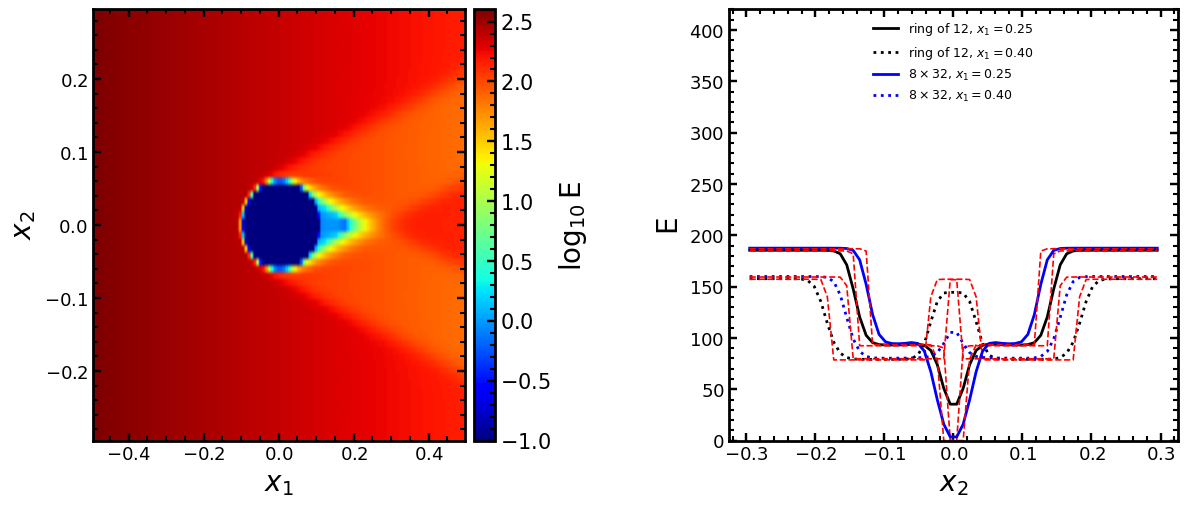

PASS idort_shadow   criterion {"near": {"L1": [0.0138, 0.05]}}
PASS idort_shadow_gl   criterion {"near": {"L1": [0.0126, 0.05]}}


In [4]:
# ---- shadow
fig, ax = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={'wspace': 0.42})
for t, c in (('idort_shadow', 'k'), ('idort_shadow_gl', 'b')):
    d = os.path.join(WORK, t, 'run'); E, Ex = vett.last_bin(d, 'vet')['vet_e'][0], rt.shadow_exact(d); x1, x2, _ = vett.cell_centres(d)
    if t == 'idort_shadow':
        im = ax[0].imshow(np.log10(np.maximum(E, 1e-3)), origin='lower', aspect='auto', extent=[x1[0], x1[-1], x2[0], x2[-1]], vmin=-1, vmax=np.log10(400), cmap='jet')
        bar(fig, im, ax[0], r'$\rm \log_{10} E$'); ax[0].set_xlabel(r'$x_1$', fontsize=LB); ax[0].set_ylabel(r'$x_2$', fontsize=LB)
    for xc, ls in ((0.25, '-'), (0.4, ':')):
        i = int(np.argmin(np.abs(x1 - xc))); ax[1].plot(x2, E[:, i], ls, c=c, lw=2, label=r'%s, $x_1 = %.2f$' % ('ring of 12' if c == 'k' else r'$8 \times 32$', x1[i])); ax[1].plot(x2, Ex[:, i], '--', c='r', lw=1.2)
ax[1].set_xlabel(r'$x_2$', fontsize=LB); ax[1].set_ylabel(r'$\rm E$', fontsize=LB); ax[1].set_ylim(0, 420); ax[1].legend(fontsize=LG - 3, loc='upper center', ncol=1)
plt.show()
for t in ('idort_shadow', 'idort_shadow_gl'):
    nb.verdict(t, res[t])